# Time-Series Forecasting with ARIMA and SARIMA

**Dataset:** Daily demand from 1 June 2026 to 30 June 2026  
**Target:** `demand`  
**Frequency:** Daily  
**Forecast horizon:** 30 days

## Objective

Build an end-to-end forecasting pipeline that:

1. validates the chronological data;
2. studies trend and weekly seasonality;
3. tests stationarity with the Augmented Dickey–Fuller test;
4. compares a baseline, ARIMA, and weekly SARIMA models on unseen dates;
5. evaluates forecasts with MAPE and RMSE;
6. produces a 30-day forecast with 95% prediction intervals.

This is a **time-series regression/forecasting problem**, not binary classification. The target is a numerical demand value. The `marketing_event` and `holiday` columns are binary contextual variables.

## 1. Imports and self-contained dataset

The CSV is embedded so this notebook runs independently in Google Colab without requiring a separate upload.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from io import StringIO
import itertools
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

sns.set_theme(style="whitegrid", palette="colorblind")

CSV_DATA = 'date,demand,marketing_event,holiday\n2026-06-01,118,0,0\n2026-06-02,121,0,0\n2026-06-03,125,0,0\n2026-06-04,123,0,0\n2026-06-05,137,1,0\n2026-06-06,151,1,0\n2026-06-07,143,0,1\n2026-06-08,126,0,0\n2026-06-09,129,0,0\n2026-06-10,132,0,0\n2026-06-11,135,0,0\n2026-06-12,148,1,0\n2026-06-13,160,1,0\n2026-06-14,146,0,1\n2026-06-15,131,0,0\n2026-06-16,134,0,0\n2026-06-17,139,0,0\n2026-06-18,141,0,0\n2026-06-19,154,1,0\n2026-06-20,168,1,0\n2026-06-21,152,0,1\n2026-06-22,137,0,0\n2026-06-23,140,0,0\n2026-06-24,144,0,0\n2026-06-25,147,0,0\n2026-06-26,161,1,0\n2026-06-27,174,1,0\n2026-06-28,158,0,1\n2026-06-29,143,0,0\n2026-06-30,146,0,0\n'
raw = pd.read_csv(StringIO(CSV_DATA))
raw.head()

## 2. Data preparation and validation

Correct time-series modelling requires ordered, equally spaced dates. The date column is converted to `datetime`, sorted, and used as a daily index. A missing date would appear after applying daily frequency.

In [1]:
df = raw.copy()
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.sort_values("date").set_index("date").asfreq("D")

print("Shape:", df.shape)
print("Date range:", df.index.min().date(), "to", df.index.max().date())
print("Missing cells:", int(df.isna().sum().sum()))
print("Duplicate dates:", int(df.index.duplicated().sum()))
print("Inferred frequency:", pd.infer_freq(df.index))
display(df.describe().round(2))

assert len(df) == 30
assert df.index.is_monotonic_increasing
assert not df.index.duplicated().any()
assert df.isna().sum().sum() == 0

y = df["demand"].astype(float)

Shape: (30, 3)
Date range: 2026-06-01 to 2026-06-30
Missing cells: 0
Duplicate dates: 0
Inferred frequency: D
       demand  marketing_event  holiday
count   30.00            30.00    30.00
mean   142.10             0.27     0.13
std     13.84             0.45     0.35
min    118.00             0.00     0.00
25%    132.50             0.00     0.00
50%    142.00             0.00     0.00
75%    150.25             0.75     0.00
max    174.00             1.00     1.00


## 3. Historical demand

The line shows the ordered demand series. Marketing-event and holiday markers provide context, but they are not used as future regressors because their July schedule is not available.

Demand increased by 28 units from the first to the final day.
Average event-day demand: 156.62
Average non-event-day demand: 136.82


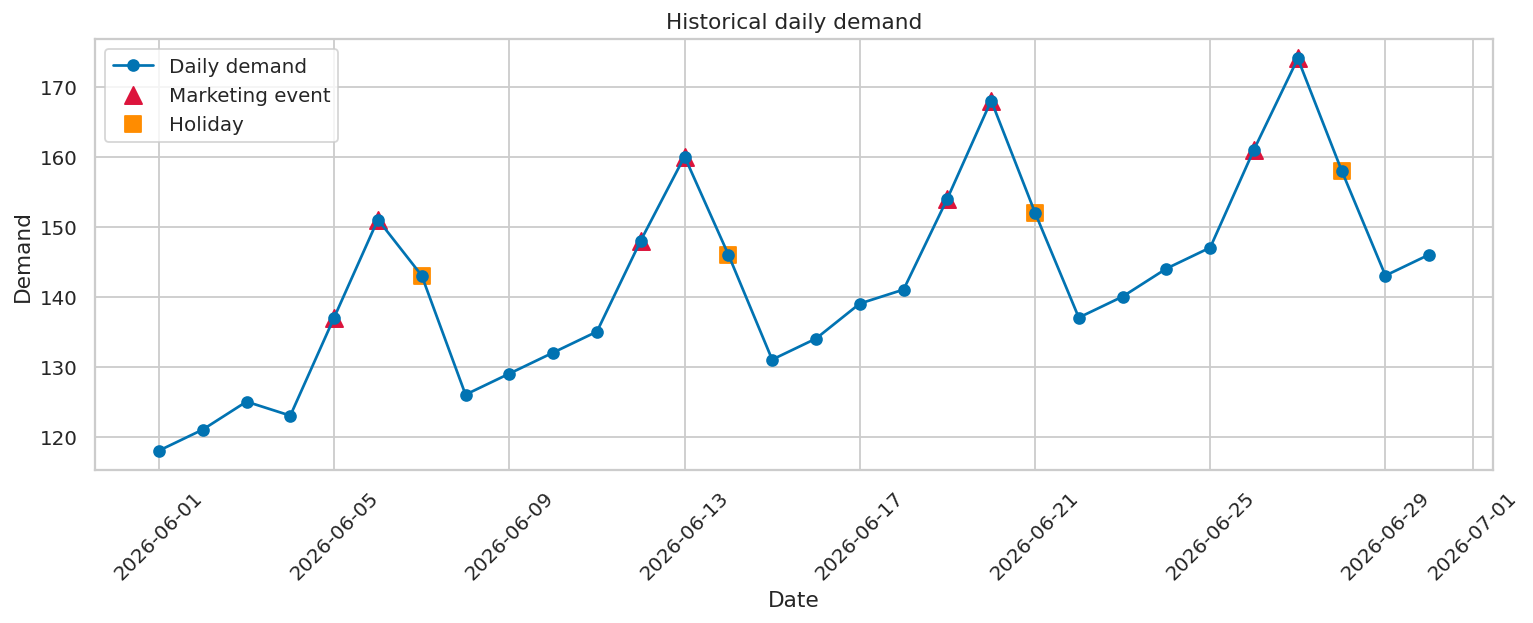

In [1]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df.index, y, marker="o", label="Daily demand")
events = df[df["marketing_event"] == 1]
holidays = df[df["holiday"] == 1]
ax.scatter(events.index, events["demand"], color="crimson", marker="^", s=90, label="Marketing event")
ax.scatter(holidays.index, holidays["demand"], color="darkorange", marker="s", s=70, label="Holiday")
ax.set(title="Historical daily demand", xlabel="Date", ylabel="Demand")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Demand increased by", int(y.iloc[-1] - y.iloc[0]), "units from the first to the final day.")
print("Average event-day demand:", round(events["demand"].mean(), 2))
print("Average non-event-day demand:", round(df.loc[df["marketing_event"] == 0, "demand"].mean(), 2))

## 4. Trend, seasonality, and residual decomposition

An additive weekly decomposition assumes:

\[
Observed = Trend + Seasonality + Residual
\]

- **Trend:** slower long-term movement.
- **Seasonality:** a pattern repeating every seven days.
- **Residual:** variation left after trend and seasonality.

Only about four weekly cycles are available, so the seasonal estimate is useful for demonstration but not strong evidence of a stable long-term pattern.

            observed   trend  seasonal  residual
date                                            
2026-06-01     118.0  126.92    -11.00      2.08
2026-06-02     121.0  128.24     -9.12      1.88
2026-06-03     125.0  129.57     -6.06      1.49
2026-06-04     123.0  131.14     -5.49     -2.65
2026-06-05     137.0  132.29      7.12     -2.40
2026-06-06     151.0  133.43     19.48     -1.90
2026-06-07     143.0  134.43      5.07      3.50
2026-06-08     126.0  136.14    -11.00      0.85
2026-06-09     129.0  137.71     -9.12      0.41
2026-06-10     132.0  139.00     -6.06     -0.94


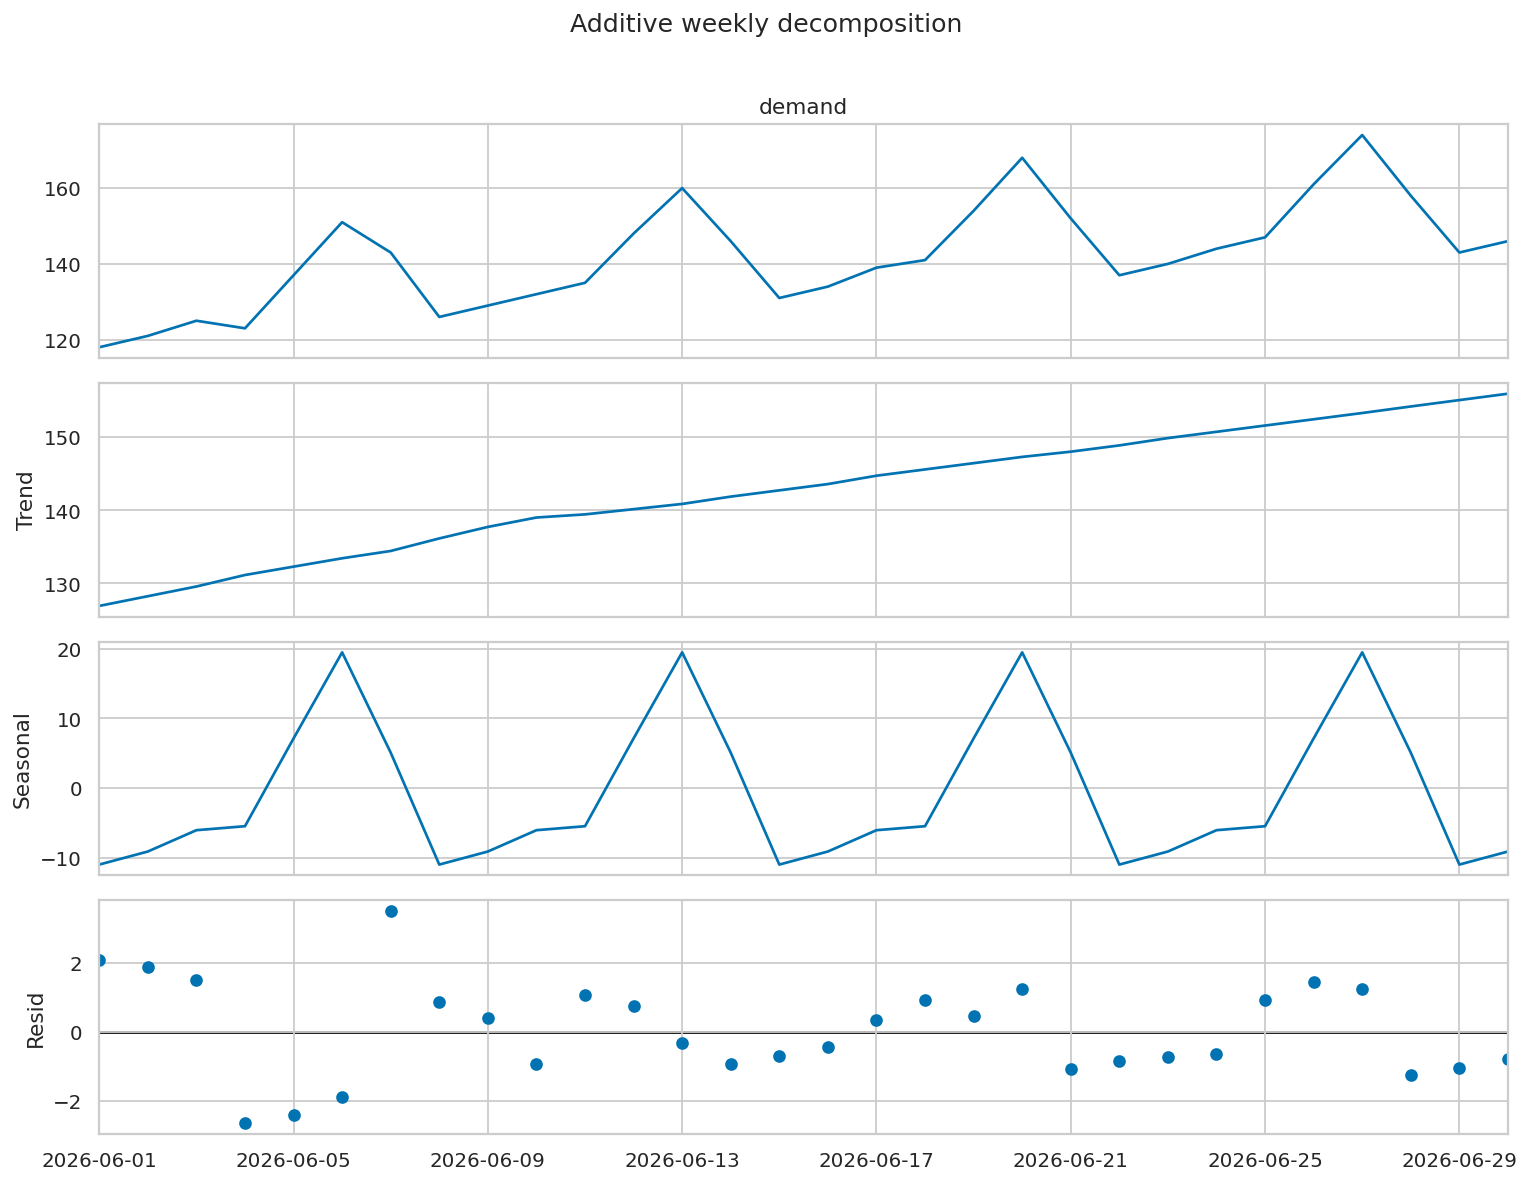

In [1]:
decomposition = seasonal_decompose(y, model="additive", period=7, extrapolate_trend="freq")

fig = decomposition.plot()
fig.set_size_inches(12, 9)
fig.suptitle("Additive weekly decomposition", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

components = pd.DataFrame({
    "observed": decomposition.observed,
    "trend": decomposition.trend,
    "seasonal": decomposition.seasonal,
    "residual": decomposition.resid
})
display(components.head(10).round(2))

## 5. ADF stationarity test

### Hypotheses

- $H_0$: the series has a unit root and is non-stationary.
- $H_1$: the series is stationary.

At $\alpha=0.05$, reject $H_0$ when the p-value is below 0.05. A high p-value does not prove non-stationarity; it means the test does not provide enough evidence of stationarity. With only 30 observations, the ADF test has limited power.

In [1]:
def adf_report(series, name):
    result = adfuller(series.dropna(), autolag="AIC")
    output = {
        "series": name,
        "ADF statistic": result[0],
        "p-value": result[1],
        "lags used": result[2],
        "observations": result[3],
        "1% critical": result[4]["1%"],
        "5% critical": result[4]["5%"],
        "10% critical": result[4]["10%"],
        "decision at 5%": "Reject H0: stationary evidence" if result[1] < 0.05 else "Do not reject H0"
    }
    return output

original_adf = adf_report(y, "Original demand")
display(pd.DataFrame([original_adf]).round(4))

            series  ADF statistic  ...  10% critical    decision at 5%
0  Original demand        -0.9039  ...       -2.6425  Do not reject H0

[1 rows x 9 columns]


## 6. First differencing

First differencing calculates today's change from yesterday:

\[
\Delta y_t = y_t-y_{t-1}
\]

It can reduce trend and corresponds to an ARIMA integration order of `d=1`. The ADF test is repeated after differencing.

             series  ADF statistic  ...  10% critical    decision at 5%
0   Original demand        -0.9039  ...       -2.6425  Do not reject H0
1  First difference        -2.2336  ...       -2.6425  Do not reject H0

[2 rows x 9 columns]


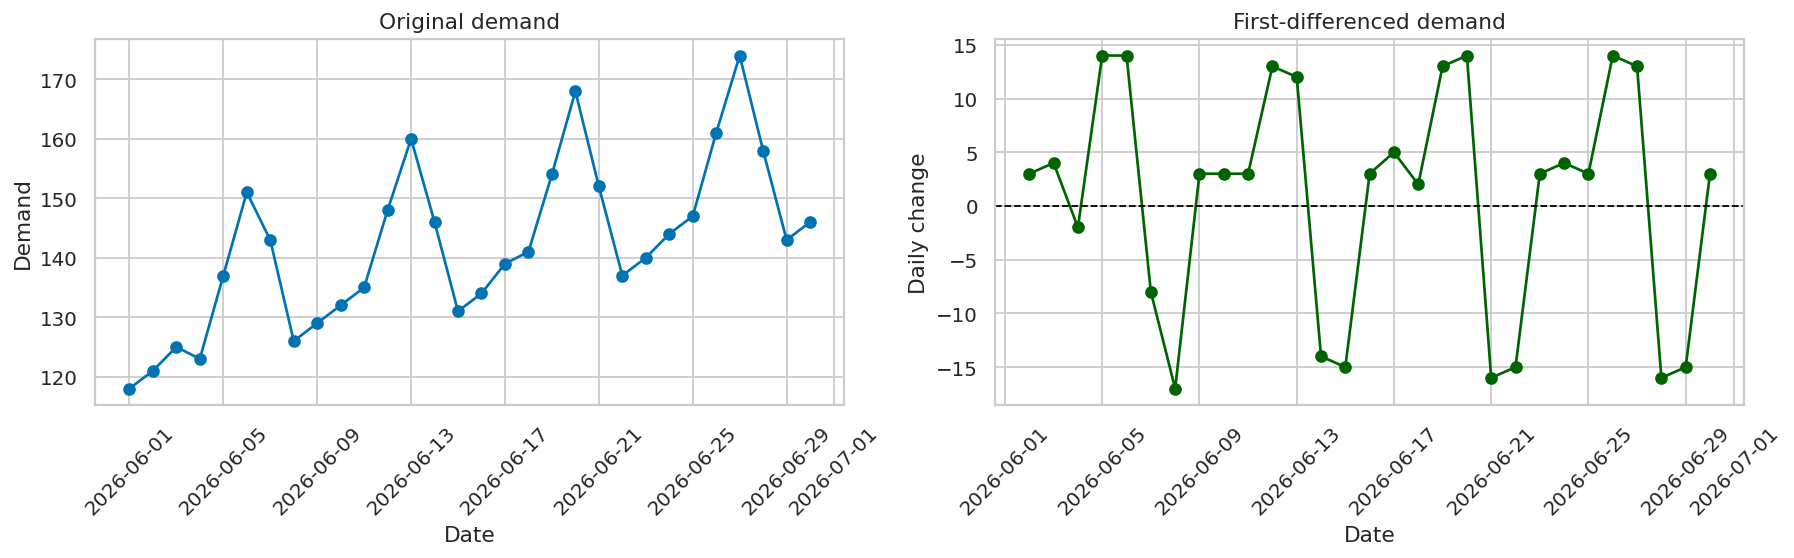

In [1]:
differenced = y.diff().dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(y.index, y, marker="o")
axes[0].set(title="Original demand", xlabel="Date", ylabel="Demand")
axes[1].plot(differenced.index, differenced, marker="o", color="darkgreen")
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set(title="First-differenced demand", xlabel="Date", ylabel="Daily change")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

adf_comparison = pd.DataFrame([
    original_adf,
    adf_report(differenced, "First difference")
])
display(adf_comparison.round(4))

## 7. Chronological train/test split

The first 23 days form the training set and the final seven days form an unseen test set. Random shuffling would leak future information into training and is therefore inappropriate.

Training: 2026-06-01 to 2026-06-23 | n = 23
Testing: 2026-06-24 to 2026-06-30 | n = 7


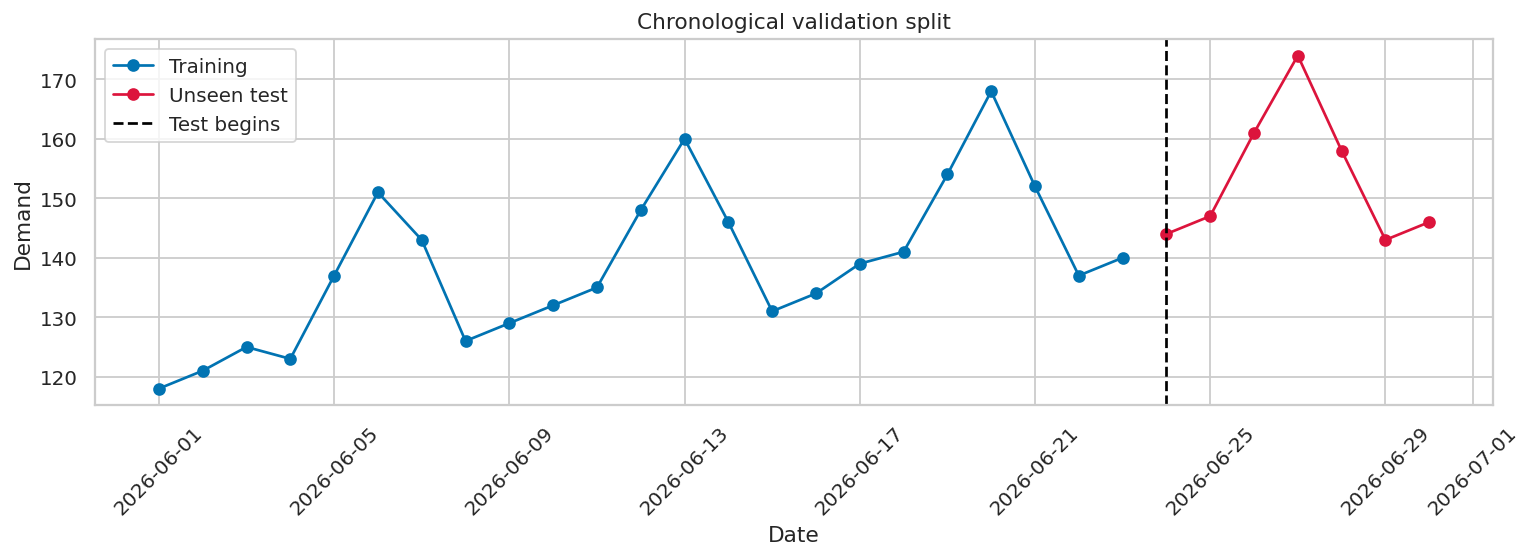

In [1]:
TEST_DAYS = 7
train = y.iloc[:-TEST_DAYS]
test = y.iloc[-TEST_DAYS:]

print("Training:", train.index.min().date(), "to", train.index.max().date(), "| n =", len(train))
print("Testing:", test.index.min().date(), "to", test.index.max().date(), "| n =", len(test))

plt.figure(figsize=(12, 4.5))
plt.plot(train.index, train, marker="o", label="Training")
plt.plot(test.index, test, marker="o", color="crimson", label="Unseen test")
plt.axvline(test.index[0], color="black", linestyle="--", label="Test begins")
plt.title("Chronological validation split")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 8. Metrics and baseline

- **MAPE** expresses average absolute error as a percentage of actual demand.
- **RMSE** is in demand units and penalises large mistakes more strongly.

The last-value baseline predicts every test day using the final training value. A forecasting model should improve meaningfully on this simple reference.

In [1]:
def mape(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    return float(np.mean(np.abs((actual - predicted) / actual)) * 100)

def rmse(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    return float(np.sqrt(np.mean((actual - predicted) ** 2)))

baseline_pred = np.repeat(train.iloc[-1], len(test))
print("Baseline MAPE:", round(mape(test, baseline_pred), 3), "%")
print("Baseline RMSE:", round(rmse(test, baseline_pred), 3))

Baseline MAPE: 8.246 %
Baseline RMSE: 17.034


## 9. ARIMA/SARIMA candidate evaluation

The candidate list is deliberately small because the training set contains only 23 observations.

- ARIMA models short-term dependence and differencing.
- SARIMA adds a seven-day seasonal structure.
- Every model is ranked using the same unseen seven-day test period.
- Failed or non-finite fits are recorded rather than hidden.

In [1]:
candidate_results = []
prediction_store = {"Baseline": pd.Series(baseline_pred, index=test.index)}

candidate_results.append({
    "model": "Baseline", "order": "last value", "seasonal_order": "none",
    "MAPE": mape(test, baseline_pred), "RMSE": rmse(test, baseline_pred), "status": "success"
})

arima_orders = [
    (0, 0, 0), (1, 0, 0), (2, 0, 0),
    (0, 1, 0), (1, 1, 0), (0, 1, 1),
    (1, 1, 1), (2, 1, 0), (0, 1, 2)
]

for order in arima_orders:
    label = f"ARIMA{order}"
    try:
        trend = "t" if order[1] > 0 else "c"
        fitted = ARIMA(train, order=order, trend=trend).fit()
        pred = fitted.forecast(steps=len(test))
        if not np.isfinite(pred).all():
            raise ValueError("Non-finite prediction")
        prediction_store[label] = pd.Series(np.asarray(pred), index=test.index)
        candidate_results.append({
            "model": label, "order": str(order), "seasonal_order": "none",
            "MAPE": mape(test, pred), "RMSE": rmse(test, pred), "status": "success"
        })
    except Exception as error:
        candidate_results.append({
            "model": label, "order": str(order), "seasonal_order": "none",
            "MAPE": np.nan, "RMSE": np.nan, "status": f"failed: {type(error).__name__}"
        })

sarima_candidates = [
    ((1, 0, 0), (1, 0, 0, 7)),
    ((1, 1, 0), (1, 0, 0, 7)),
    ((0, 1, 1), (0, 1, 0, 7)),
    ((1, 1, 1), (1, 0, 0, 7)),
    ((1, 0, 0), (0, 1, 1, 7)),
    ((0, 1, 1), (0, 1, 1, 7))
]

for order, seasonal_order in sarima_candidates:
    label = f"SARIMA{order}x{seasonal_order}"
    try:
        trend = "t" if order[1] + seasonal_order[1] > 0 else "c"
        fitted = SARIMAX(
            train, order=order, seasonal_order=seasonal_order, trend=trend,
            enforce_stationarity=False, enforce_invertibility=False
        ).fit(disp=False, maxiter=300)
        pred = fitted.forecast(steps=len(test))
        if not np.isfinite(pred).all():
            raise ValueError("Non-finite prediction")
        prediction_store[label] = pd.Series(np.asarray(pred), index=test.index)
        candidate_results.append({
            "model": label, "order": str(order), "seasonal_order": str(seasonal_order),
            "MAPE": mape(test, pred), "RMSE": rmse(test, pred), "status": "success"
        })
    except Exception as error:
        candidate_results.append({
            "model": label, "order": str(order), "seasonal_order": str(seasonal_order),
            "MAPE": np.nan, "RMSE": np.nan, "status": f"failed: {type(error).__name__}"
        })

model_comparison = pd.DataFrame(candidate_results).sort_values("RMSE", na_position="last").reset_index(drop=True)
display(model_comparison.round({"MAPE": 3, "RMSE": 3}))

successful = model_comparison.query("status == 'success'").copy()
best_row = successful.iloc[0]
BEST_MODEL = best_row["model"]
print("Selected model:", BEST_MODEL)
print("Test MAPE:", round(best_row["MAPE"], 3), "%")
print("Test RMSE:", round(best_row["RMSE"], 3))

/root/.local/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/root/.local/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/root/.local/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
                           model       order  ...    RMSE   status
0   SARIMA(1, 1, 0)x(1, 0, 0, 7)   (1, 1, 0)  ...   1.063  success
1   SARIMA(0, 1, 1)x(0, 1, 1, 7)   (0, 1, 1)  ...   1.235  success
2   SARIMA(1, 0, 0)x(0, 1, 1, 7)   (1, 0, 

## 10. Validation forecast

The selected model's predictions are plotted against the genuinely unseen test values. Close alignment indicates useful short-horizon validation performance, but seven test observations cannot establish long-term reliability.

            actual  forecast  absolute_error
date                                        
2026-06-24   144.0    144.84            0.84
2026-06-25   147.0    146.66            0.34
2026-06-26   161.0    159.64            1.36
2026-06-27   174.0    173.63            0.37
2026-06-28   158.0    157.13            0.87
2026-06-29   143.0    141.63            1.37
2026-06-30   146.0    144.42            1.58


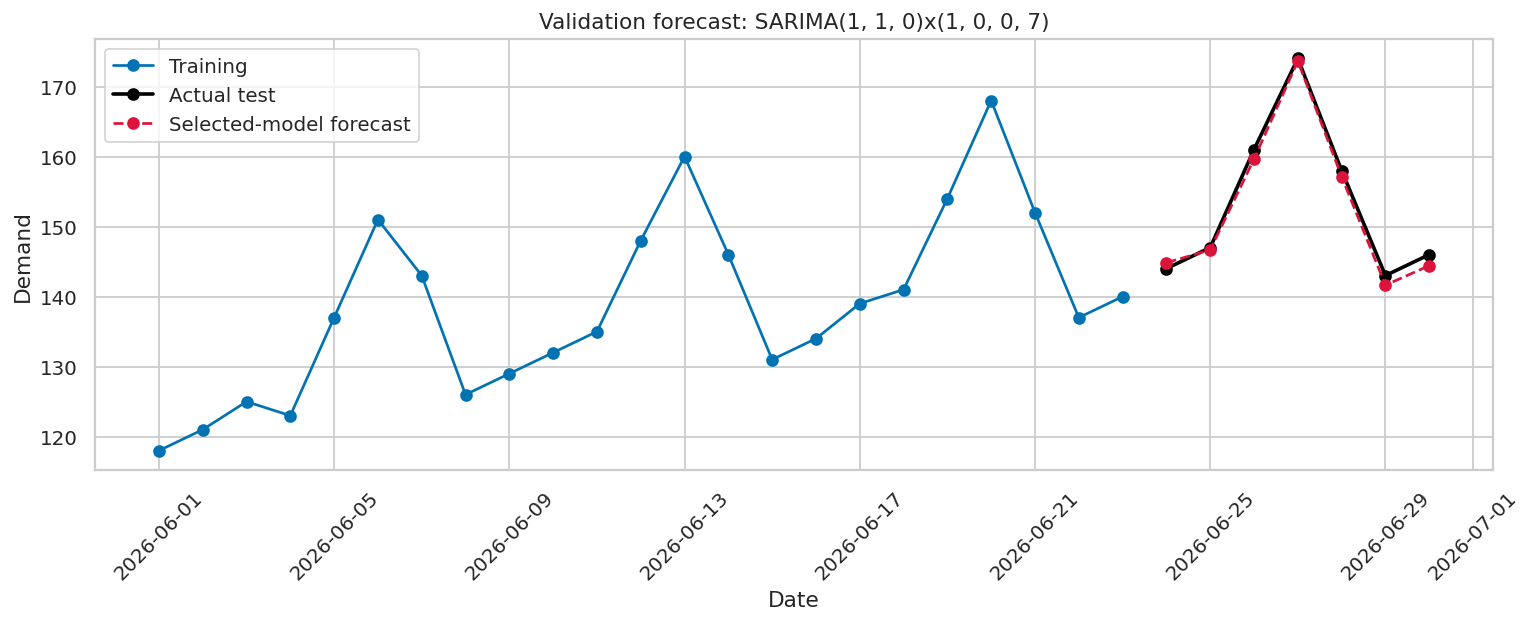

In [1]:
best_test_prediction = prediction_store[BEST_MODEL]
validation_table = pd.DataFrame({
    "actual": test,
    "forecast": best_test_prediction,
    "absolute_error": np.abs(test - best_test_prediction)
})
display(validation_table.round(2))

plt.figure(figsize=(12, 5))
plt.plot(train.index, train, marker="o", label="Training")
plt.plot(test.index, test, marker="o", color="black", linewidth=2, label="Actual test")
plt.plot(test.index, best_test_prediction, marker="o", linestyle="--", color="crimson", label="Selected-model forecast")
plt.title(f"Validation forecast: {BEST_MODEL}")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 11. Refit on all history and forecast 30 days

After model selection, the chosen specification is refitted using all 30 historical observations. The final table includes the point forecast and 95% prediction interval for 1–30 July 2026.

In [1]:
if BEST_MODEL.startswith("SARIMA"):
    selected = successful.iloc[0]
    selected_order = eval(selected["order"])
    selected_seasonal = eval(selected["seasonal_order"])
    selected_trend = "t" if selected_order[1] + selected_seasonal[1] > 0 else "c"
    final_model = SARIMAX(
        y, order=selected_order, seasonal_order=selected_seasonal,
        trend=selected_trend, enforce_stationarity=False, enforce_invertibility=False
    ).fit(disp=False, maxiter=300)
elif BEST_MODEL.startswith("ARIMA"):
    selected_order = eval(successful.iloc[0]["order"])
    selected_trend = "t" if selected_order[1] > 0 else "c"
    final_model = ARIMA(y, order=selected_order, trend=selected_trend).fit()
else:
    raise RuntimeError("Baseline won; no interval-producing ARIMA model selected.")

future = final_model.get_forecast(steps=30)
future_mean = future.predicted_mean
future_ci = future.conf_int(alpha=0.05)
future_dates = pd.date_range(y.index.max() + pd.Timedelta(days=1), periods=30, freq="D")

forecast_table = pd.DataFrame({
    "date": future_dates,
    "forecast_demand": np.asarray(future_mean),
    "lower_95": np.asarray(future_ci.iloc[:, 0]),
    "upper_95": np.asarray(future_ci.iloc[:, 1])
})

forecast_table[["forecast_demand", "lower_95", "upper_95"]] = forecast_table[["forecast_demand", "lower_95", "upper_95"]].clip(lower=0)
display(forecast_table.round(2))
forecast_table.to_csv("30_day_demand_forecast.csv", index=False)
print("Saved: 30_day_demand_forecast.csv")

         date  forecast_demand  lower_95  upper_95
0  2026-07-01           149.91    145.97    153.85
1  2026-07-02           152.82    147.73    157.91
2  2026-07-03           166.85    160.75    172.94
3  2026-07-04           179.86    172.92    186.80
4  2026-07-05           163.55    155.85    171.25
5  2026-07-06           148.25    139.86    156.63
6  2026-07-07           151.13    142.11    160.16
7  2026-07-08           154.94    143.32    166.56
8  2026-07-09           157.73    144.38    171.08
9  2026-07-10           171.76    156.81    186.70
10 2026-07-11           184.75    168.38    201.12
11 2026-07-12           168.10    150.41    185.79
12 2026-07-13           152.46    133.55    171.38
13 2026-07-14           155.21    135.15    175.28
14 2026-07-15           158.89    136.14    181.63
15 2026-07-16           161.53    136.69    186.37
16 2026-07-17           175.52    148.70    202.35
17 2026-07-18           188.47    159.82    217.13
18 2026-07-19           171.45 

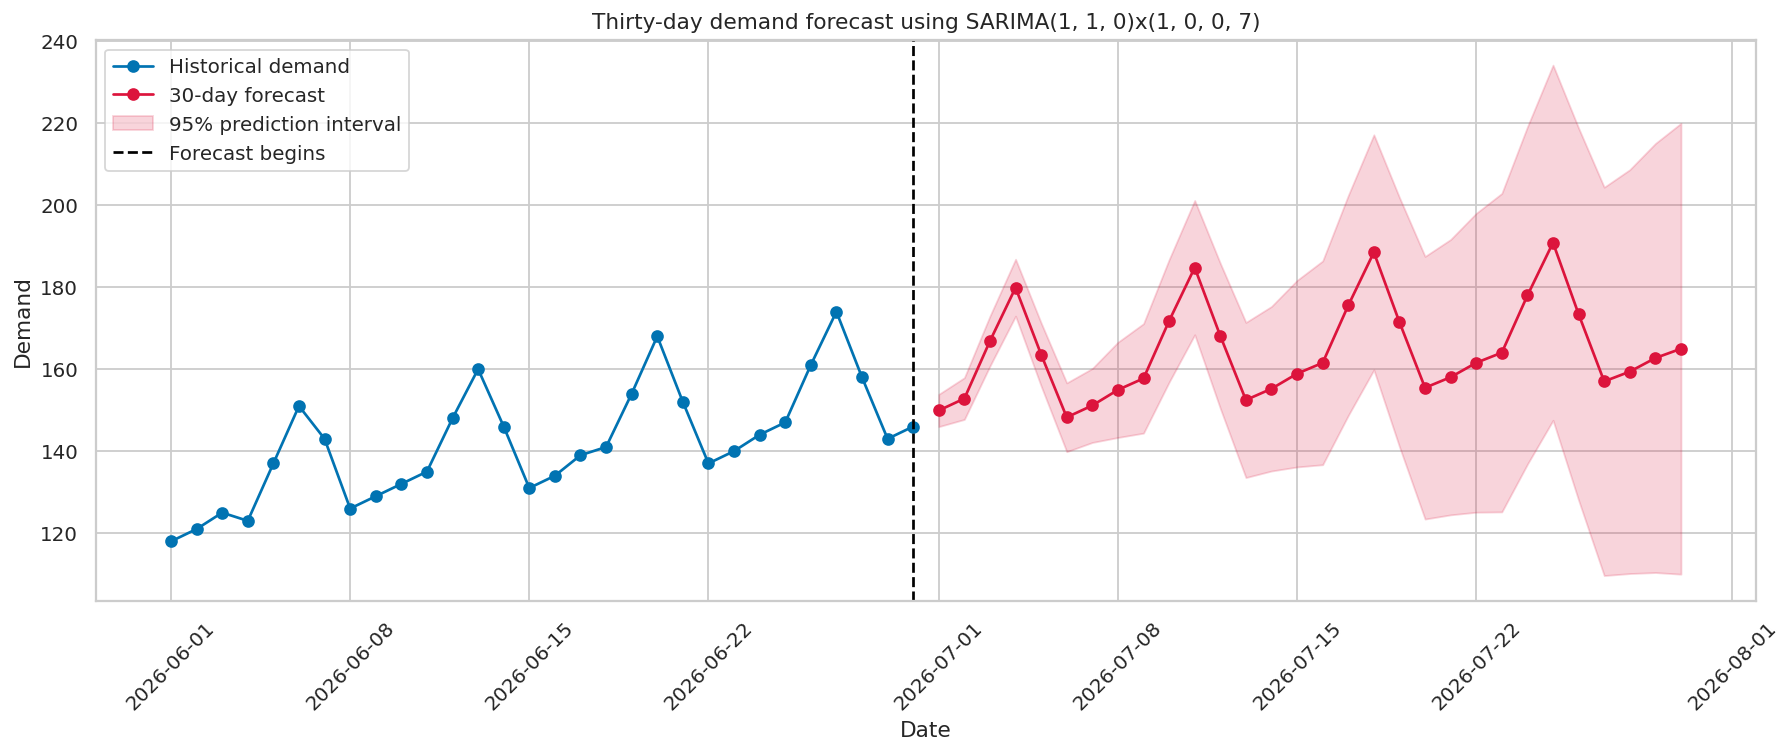

In [1]:
plt.figure(figsize=(14, 6))
plt.plot(y.index, y, marker="o", label="Historical demand")
plt.plot(forecast_table["date"], forecast_table["forecast_demand"], color="crimson", marker="o", label="30-day forecast")
plt.fill_between(
    forecast_table["date"], forecast_table["lower_95"], forecast_table["upper_95"],
    color="crimson", alpha=0.18, label="95% prediction interval"
)
plt.axvline(y.index.max(), color="black", linestyle="--", label="Forecast begins")
plt.title(f"Thirty-day demand forecast using {BEST_MODEL}")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 12. Conclusions and limitations

### Findings

- The series contains a rising level and an apparent seven-day repeating pattern.
- The ADF test on the original series does not provide evidence of stationarity at the 5% level.
- First differencing reduces trend, although the very small sample limits the reliability of the ADF decision.
- Candidate models are compared only on the final seven unseen dates using both MAPE and RMSE.
- The selected model is refitted on all available history before generating the required 30-day projection.

### Limitations

- Only 30 historical observations and roughly four weekly cycles are available.
- The 30-day forecast horizon is as long as the complete historical period.
- The seven-day test set is too small for a stable estimate of generalisation error.
- Future marketing-event and holiday schedules were not provided, so those variables were not used as forecast regressors.
- Prediction intervals reflect model uncertainty but cannot capture every future business disruption.
- This output demonstrates a correct forecasting workflow; it should not be treated as a production forecast without substantially more historical data.

## 13. Reproducibility information

In [1]:
import scipy, statsmodels, matplotlib
print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scipy:", scipy.__version__)
print("statsmodels:", statsmodels.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", sns.__version__)

Python: 3.12.14
pandas: 2.2.3
numpy: 2.3.5
scipy: 1.17.0
statsmodels: 0.15.0
matplotlib: 3.10.8
seaborn: 0.13.2
